# 01 · Comprensión del problema, EDA y preprocesamiento
**Evento Evaluativo 4 · Detección de fraude en transacciones electrónicas (IEEE-CIS)**

## 1. Descripción del problema
> En una plataforma de pagos en línea, algunas transacciones son fraudulentas: alguien usa una tarjeta o una identidad que no es suya. Cada fraude que pasa le cuesta dinero a la plataforma y a la persona afectada. Pero equivocarse hacia el otro lado también cuesta: bloquear una compra legítima molesta a un cliente real. El reto es detectar el fraude sin frenar las compras normales.
>
> Lo difícil es que el fraude es muy poco frecuente, alrededor de 3,5 de cada 100 transacciones. Un modelo ingenuo que dijera "todo es legítimo" acertaría cerca del 96 % de las veces y no serviría de nada. Trabajamos con los datos de la competencia IEEE-CIS Fraud Detection: más de 590.000 transacciones y unas 430 columnas, la mayoría anonimizadas.

**Preguntas que queremos responder:**
1. ¿Se puede estimar la probabilidad de que una transacción sea fraudulenta? ¿Con qué calidad?
2. ¿Qué características de la transacción, del medio de pago o del dispositivo se asocian con el fraude?
3. Sin usar la etiqueta, ¿existen grupos o transacciones atípicas que coincidan con el fraude?
4. ¿Cuánto cuesta equivocarse en cada sentido (falso positivo vs falso negativo)?

In [1]:
import os, sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

RAIZ = Path("..").resolve()         
sys.path.append(str(RAIZ))
from src import preprocesamiento as pp

DATA_DIR = RAIZ / "data" / "raw"      
PROC_DIR = RAIZ / "data" / "processed" 
RES_DIR = RAIZ / "resultados"         
SEED = 42
N_MUESTRA = int(os.environ.get("N_MUESTRA", 150_000))

## Datos
Los datos son los de la competencia *IEEE-CIS Fraud Detection* de Kaggle. Se descargaron desde la página de la competencia y se guardaron en `data/raw/` los dos archivos que usamos: `train_transaction.csv` y `train_identity.csv`.

## 2. Comprensión de los datos
El dataset tiene dos archivos que se unen por `TransactionID`:
- `train_transaction.csv`: monto, producto, tarjeta, direcciones, correos y cientos de variables anónimas (`C*`, `D*`, `M*`, `V*`).
- `train_identity.csv`: información de dispositivo y red. **No existe para todas las transacciones**, así que la unión es *left join*.

`TransactionDT` es un tiempo relativo en segundos (no una fecha real): sirve para ordenar y dividir por tiempo.

In [2]:
df = pp.cargar_datos(DATA_DIR)
print("Filas x columnas:", df.shape)
print(f"Transacciones con datos de identidad: {df['id_01'].notna().mean():.1%}")
print(f"Tasa de fraude total: {df[pp.TARGET].mean():.2%}")
df.head()

Filas x columnas: (590540, 434)
Transacciones con datos de identidad: 24.4%
Tasa de fraude total: 3.50%


,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,...,samsung browser 6.2,32.0,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M


## 3. Muestra y división por tiempo (decisión metodológica)
- **Muestra aleatoria** de `N_MUESTRA` filas: el dataset completo es muy grande para trabajar cómodamente. Un muestreo aleatorio conserva la proporción de fraude; verificamos que sea así.
- **División por tiempo (70 % más antiguo = entrenamiento, 30 % más reciente = prueba):** en producción un modelo se entrena con el pasado y se usa en el futuro. Un corte aleatorio mezclaría ambos y daría resultados optimistas.
- **Todo el EDA se hace solo sobre el entrenamiento**, para no "mirar" la prueba.

In [3]:
tasa_total = df[pp.TARGET].mean()
train, test = pp.muestrear_y_dividir(df, N_MUESTRA, SEED)
del df
print(f"Tasa de fraude -> completo: {tasa_total:.2%} | train: {train[pp.TARGET].mean():.2%} | test: {test[pp.TARGET].mean():.2%}")
print(f"Filas -> train: {len(train):,} | test: {len(test):,}")
train = pp.agregar_features(train)
test = pp.agregar_features(test)
PROC_DIR.mkdir(parents=True, exist_ok=True)
train.drop(columns=["hora", "dia_semana", "log_monto"]).to_pickle(PROC_DIR / "train.pkl")
test.drop(columns=["hora", "dia_semana", "log_monto"]).to_pickle(PROC_DIR / "test.pkl")

Tasa de fraude -> completo: 3.50% | train: 3.58% | test: 3.60%
Filas -> train: 105,000 | test: 45,000


## 4. Análisis exploratorio (solo entrenamiento)

### 4.1 Variable objetivo y desbalance

isFraud
0    101238
1      3762
Name: count, dtype: int64 

Proporción fraude: 3.58%  (1 de cada 28)


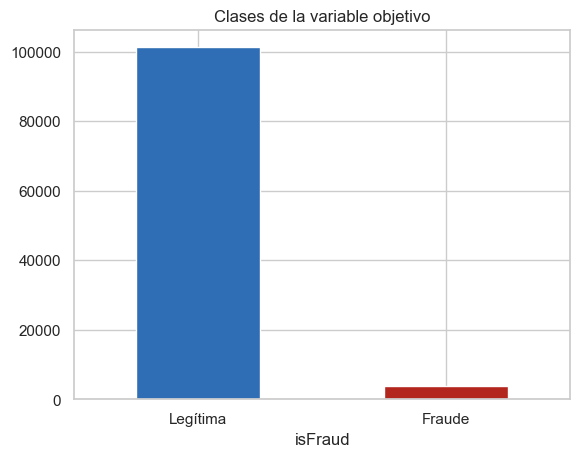

In [4]:
conteo = train[pp.TARGET].value_counts()
print(conteo, "\n")
print(f"Proporción fraude: {train[pp.TARGET].mean():.2%}  (1 de cada {1/train[pp.TARGET].mean():.0f})")
ax = conteo.rename({0: "Legítima", 1: "Fraude"}).plot(kind="bar", color=["#2F6DB5", "#B3261E"])
ax.set_title("Clases de la variable objetivo"); plt.xticks(rotation=0); plt.show()

**Hallazgo 1 · El fraude es poco frecuente.** En el entrenamiento hay 3.762 fraudes frente a 101.238 transacciones legítimas, es decir, 1 de cada 28 (3,58 %). Por eso medir con el porcentaje de aciertos (*accuracy*) engaña: un modelo que marcara todo como legítimo acertaría más del 96 % de las veces sin detectar un solo fraude. Para evaluar de verdad usaremos métricas que miran los fraudes en sí: PR-AUC, recall y precision.

### 4.2 Valores faltantes

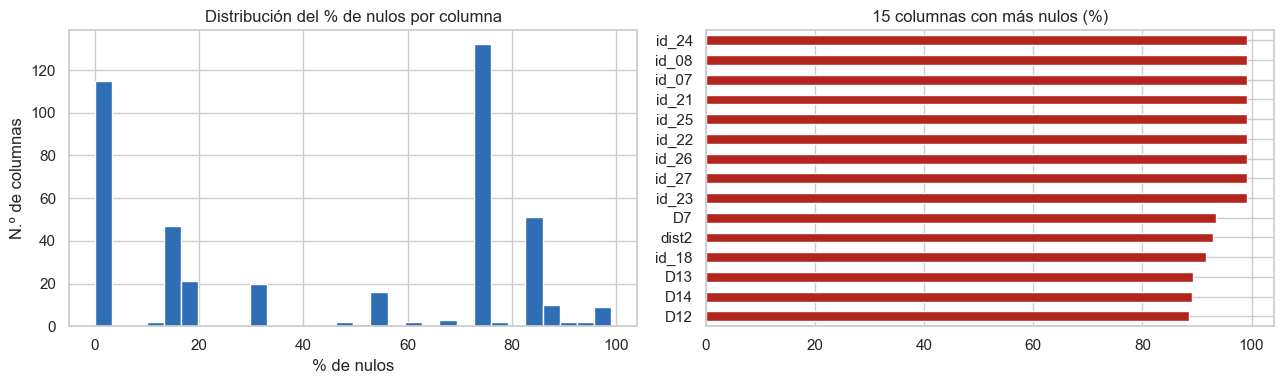

Columnas con más de 50 % de nulos: 229 de 437


In [5]:
nulos = (train.isna().mean() * 100).sort_values(ascending=False)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(nulos, bins=30, color="#2F6DB5"); ax[0].set_title("Distribución del % de nulos por columna")
ax[0].set_xlabel("% de nulos"); ax[0].set_ylabel("N.º de columnas")
nulos.head(15).sort_values().plot(kind="barh", ax=ax[1], color="#B3261E"); ax[1].set_title("15 columnas con más nulos (%)")
plt.tight_layout(); plt.show()
print("Columnas con más de 50 % de nulos:", int((nulos > 50).sum()), "de", train.shape[1])

**Hallazgo 2 · Faltan muchos datos, y que falten también dice algo.** 229 de las 437 columnas tienen más de la mitad de sus valores vacíos. Buena parte viene de que los datos de identidad (dispositivo, navegador, red) solo existen para el 24,4 % de las transacciones. Y no faltan al azar: las transacciones que sí tienen identidad registrada tienen 7,6 % de fraude, contra 2,1 % de las que no la tienen. Es decir, que un dato exista o no ya aporta información. Por eso no borramos a ciegas: solo quitamos las columnas casi vacías (más de 90 % de nulos) y a las categóricas les damos una categoría "desconocido" en lugar de descartar esas filas.

In [6]:
# ¿Tener datos de identidad se asocia con fraude?
train["tiene_identidad"] = train["id_01"].notna().astype(int)
print(train.groupby("tiene_identidad")[pp.TARGET].agg(["mean", "count"]).rename(columns={"mean": "tasa_fraude", "count": "n"}))
train = train.drop(columns="tiene_identidad")

                 tasa_fraude      n
tiene_identidad                    
0                   0.021126  76920
1                   0.076104  28080


### 4.3 Tipos de variables y cardinalidad

In [7]:
print(train.dtypes.value_counts(), "\n")
card = train.select_dtypes("object").nunique().sort_values(ascending=False)
print("Cardinalidad de las variables categóricas:")
print(card.to_string())

float64    400
str         31
int64        6
Name: count, dtype: int64 

Cardinalidad de las variables categóricas:
DeviceInfo       997
id_33            108
id_31             97
id_30             71
R_emaildomain     60
P_emaildomain     59
ProductCD          5
card6              4
card4              4
id_34              4
id_15              3
M4                 3
id_23              3
M2                 2
M1                 2
id_12              2
M9                 2
M8                 2
M7                 2
M6                 2
M5                 2
M3                 2
id_27              2
id_28              2
id_29              2
id_16              2
id_35              2
id_36              2
id_37              2
id_38              2
DeviceType         2


**Hallazgo 3 · Algunas variables tienen demasiadas categorías.** De las 31 variables de texto, la mayoría tiene entre 2 y 5 categorías, pero `DeviceInfo` tiene 997 modelos de dispositivo distintos, `id_33` tiene 108, `id_31` tiene 97 y `id_30` tiene 71 (según la descripción de la competencia, son la resolución de pantalla, el navegador y el sistema operativo). Si creáramos una columna por cada categoría, la tabla se llenaría de columnas casi vacías y los modelos serían más lentos y propensos a memorizar. Por eso, al codificar, agrupamos en una sola categoría las que aparecen en menos del 1 % de las transacciones.

### 4.4 Fraude según variables relevantes

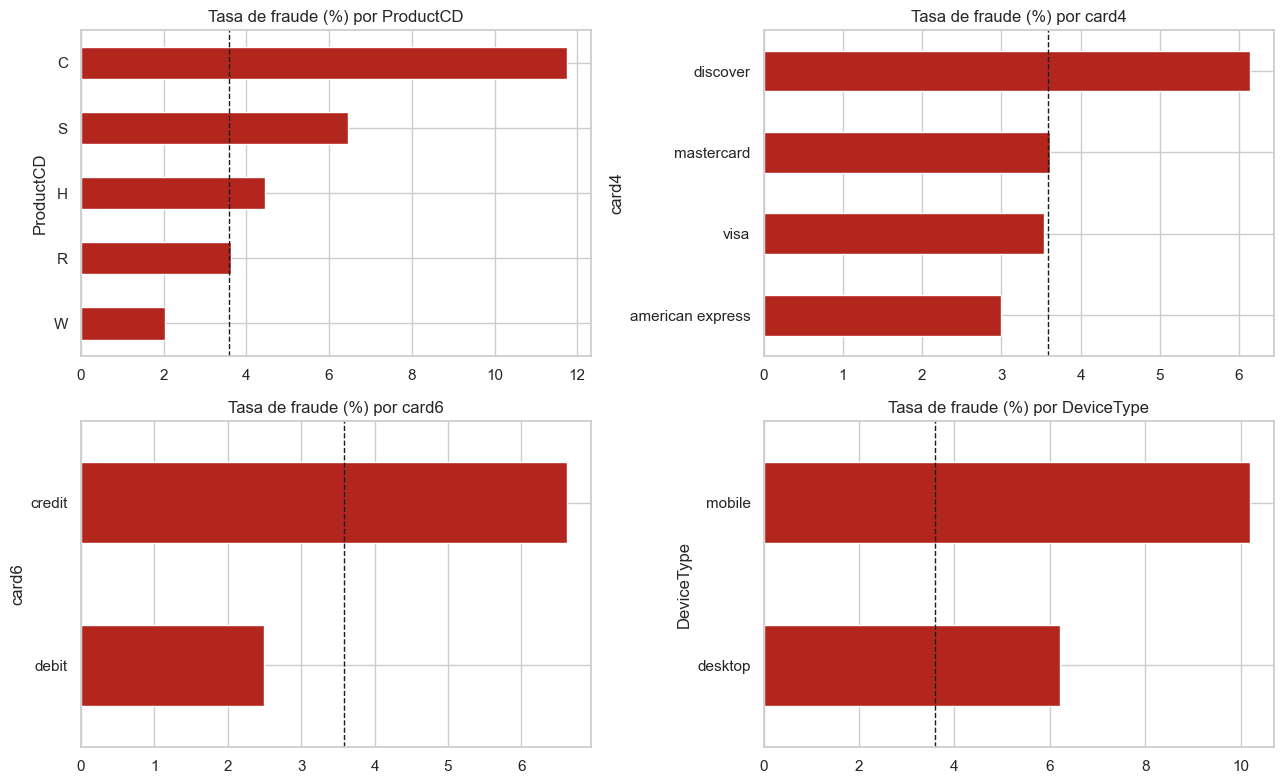

In [8]:
def tasa_por(col, minimo=100, top=10, ax=None):
    t = (train.groupby(col)[pp.TARGET].agg(["mean", "count"])
         .query("count >= @minimo").sort_values("mean", ascending=False).head(top))
    if t.empty:
        ax.set_title(f"{col}: ningún grupo con al menos {minimo} transacciones"); return t
    t["mean"].mul(100).sort_values().plot(kind="barh", ax=ax, color="#B3261E")
    ax.set_title(f"Tasa de fraude (%) por {col}"); ax.axvline(train[pp.TARGET].mean() * 100, color="k", ls="--", lw=1)
    return t

fig, ax = plt.subplots(2, 2, figsize=(13, 8))
for a, c in zip(ax.ravel(), ["ProductCD", "card4", "card6", "DeviceType"]):
    if c in train.columns: tasa_por(c, ax=a)
plt.tight_layout(); plt.show()

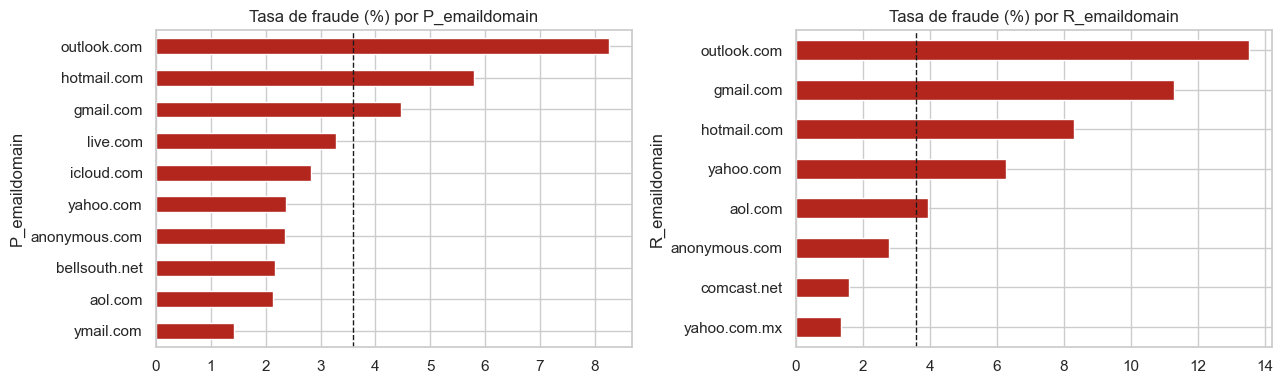

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
tasa_por("P_emaildomain", minimo=300, ax=ax[0])
tasa_por("R_emaildomain", minimo=300, ax=ax[1])
plt.tight_layout(); plt.show()

### 4.5 Monto y tiempo

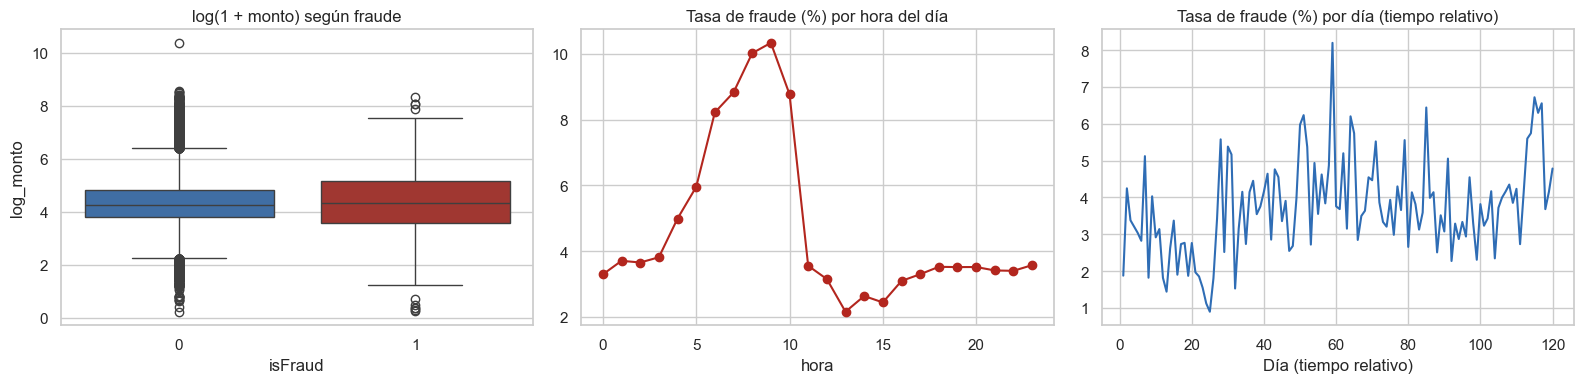

            count   mean    std  min   25%   50%    75%      max
isFraud                                                         
0        101238.0  134.2  250.0  0.3  43.4  69.0  125.0  31937.4
1          3762.0  139.1  200.5  0.3  34.0  75.0  171.0   4191.0


In [10]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.boxplot(data=train, x=pp.TARGET, y="log_monto", ax=ax[0], palette=["#2F6DB5", "#B3261E"])
ax[0].set_title("log(1 + monto) según fraude")
(train.groupby("hora")[pp.TARGET].mean() * 100).plot(ax=ax[1], marker="o", color="#B3261E")
ax[1].set_title("Tasa de fraude (%) por hora del día")
dia = (train["TransactionDT"] // 86400)
(train.groupby(dia)[pp.TARGET].mean() * 100).plot(ax=ax[2], color="#2F6DB5")
ax[2].set_title("Tasa de fraude (%) por día (tiempo relativo)")
ax[2].set_xlabel("Día (tiempo relativo)")
plt.tight_layout(); plt.show()
print(train.groupby(pp.TARGET)["TransactionAmt"].describe().round(1))

**Hallazgo 4 · El fraude no se reparte parejo, pero el monto casi no lo separa.**
- **Producto:** el producto C tiene cerca de 12 % de fraude y el W cerca de 2 %.
- **Tarjeta:** las tarjetas de crédito tienen cerca de 6,6 % de fraude y las de débito cerca de 2,5 %.
- **Dispositivo:** desde móvil cerca de 10 %, desde escritorio cerca de 6 %.
- **Correo:** outlook.com es el dominio con más fraude, tanto en el comprador (cerca de 8 %) como en el destinatario (cerca de 13 %).
- **Monto:** la mediana es 75 en fraude y 69 en legítimas, y las cajas casi se superponen: el monto por sí solo no distingue el fraude. Hay valores atípicos grandes en ambos lados (hasta unos 31.900 en una legítima). No los eliminamos porque no sabemos que sean errores y, en fraude, un monto raro puede ser justamente la señal; por eso usamos el logaritmo del monto, que reduce su peso sin quitarlos.
- **Hora:** el fraude sube hasta cerca de 10 % entre las 8 y las 9 y baja a cerca de 2 % por la tarde. Hay que tomarlo con cuidado, porque `TransactionDT` es un tiempo relativo y no la hora real del reloj.
- **Tiempo:** la tasa diaria sube y baja entre 1 % y 8 % y es algo más alta al final. Como cambia, tiene sentido entrenar con lo antiguo y probar con lo reciente.
- **Variables anónimas:** las más correlacionadas con el fraude son `V257`, `V201` y `V158`. Predicen, pero no sabemos qué miden, así que no se pueden interpretar.

### 4.6 Relaciones numéricas con el fraude

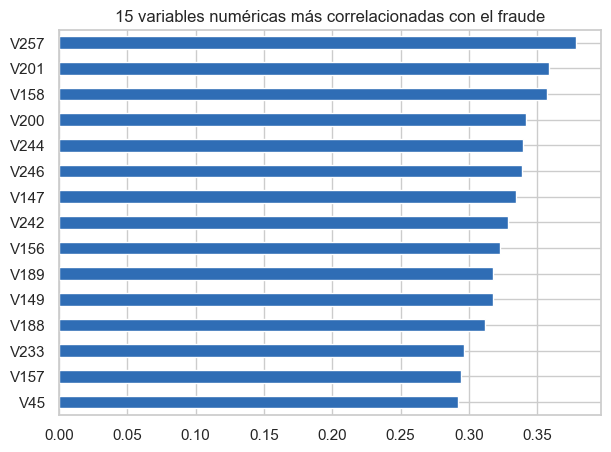

In [11]:
numericas = train.select_dtypes("number").drop(columns=[pp.TARGET, "TransactionID"])
corr = numericas.sample(min(30_000, len(numericas)), random_state=SEED).corrwith(
    train.loc[numericas.sample(min(30_000, len(numericas)), random_state=SEED).index, pp.TARGET])
top = corr.abs().sort_values(ascending=False).head(15)
corr[top.index].sort_values().plot(kind="barh", figsize=(7, 5), color="#2F6DB5")
plt.title("15 variables numéricas más correlacionadas con el fraude"); plt.show()

## 5. Preprocesamiento
Decisiones (todas se ajustan **solo con el entrenamiento**; ver `src/preprocesamiento.py`):

| Paso | Decisión | Por qué |
|---|---|---|
| Columnas casi vacías | Se eliminan las de más de 90 % de nulos | No aportan información fiable |
| Columnas constantes | Se eliminan | No distinguen nada |
| Numéricas muy correlacionadas | Se elimina una de cada par con correlación mayor a 0,95 | Reduce redundancia y dimensionalidad |
| Nulos numéricos | Mediana (modelos lineales) o se dejan como nulo (árboles) | Los árboles los tratan solos |
| Nulos categóricos | Categoría "desconocido" | Un nulo puede ser informativo |
| Categóricas | One-hot agrupando categorías de menos de 1 % (lineales) / codificación ordinal (árboles) | Controla la alta cardinalidad |
| Escalado | Estandarización (solo modelos lineales, K-Means y PCA) | Dependen de la escala |
| Variables nuevas | hora, día de la semana y log del monto | Capturan patrones temporales y reducen el sesgo del monto |

In [12]:
num, cat, informe = pp.seleccionar_columnas(train)
print("Resumen de la selección de columnas:", informe)
print(f"Numéricas conservadas: {len(num)} | Categóricas conservadas: {len(cat)}")

pre = pp.preprocesador_lineal(num, cat)
Z_train = pre.fit_transform(train[num + cat])   # fit SOLO con train
Z_test = pre.transform(test[num + cat])         # a test solo se le aplica
print(f"Matriz para modelos lineales -> train: {Z_train.shape} | test: {Z_test.shape}")

Resumen de la selección de columnas: {'inicial': 434, 'quitadas_por_nulos': 12, 'quitadas_por_constantes': 1, 'quitadas_por_correlacion': 110, 'final': 311}
Numéricas conservadas: 282 | Categóricas conservadas: 29
Matriz para modelos lineales -> train: (105000, 398) | test: (45000, 398)


## 6. Selección de variables y reducción de dimensionalidad
La selección ya ocurrió arriba (nulos, constantes, correlación). Ahora medimos cuánta información conservan pocas componentes con **PCA**, que también se usa en el notebook no supervisado.

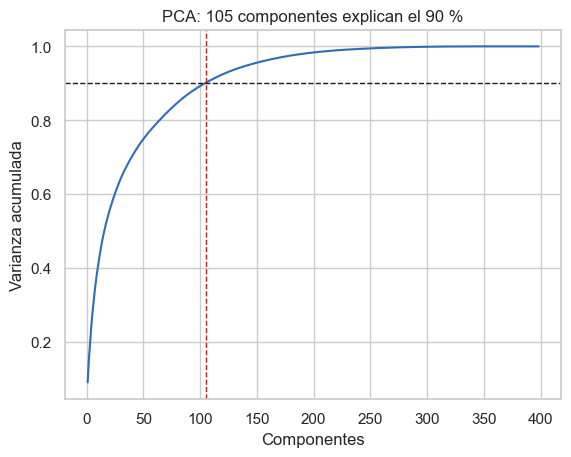

De 398 columnas procesadas bastan 105 componentes para conservar el 90 % de la varianza.


In [13]:
from sklearn.decomposition import PCA
pca = PCA(random_state=SEED).fit(Z_train)
acum = np.cumsum(pca.explained_variance_ratio_)
n90 = int(np.searchsorted(acum, 0.90) + 1)
plt.plot(range(1, len(acum) + 1), acum, color="#2F6DB5")
plt.axhline(0.90, color="k", ls="--", lw=1); plt.axvline(n90, color="#B3261E", ls="--", lw=1)
plt.xlabel("Componentes"); plt.ylabel("Varianza acumulada"); plt.title(f"PCA: {n90} componentes explican el 90 %")
plt.show()
print(f"De {Z_train.shape[1]} columnas procesadas bastan {n90} componentes para conservar el 90 % de la varianza.")

## 7. Conclusiones de este notebook
- **El problema:** detectar fraude sin molestar a clientes legítimos, con un fraude raro (3,5 % de las transacciones).
- **Lo que más importa del EDA:** el desbalance (1 de cada 28) obliga a usar PR-AUC, recall y precision; el fraude se concentra en ciertos productos, tipos de tarjeta, dispositivos y correos; tener datos de identidad se asocia con más fraude (7,6 % contra 2,1 %); el monto casi no distingue el fraude; y muchas variables son anónimas.
- **Preprocesamiento:** muestra aleatoria de 150.000 transacciones que conserva la proporción de fraude; división por tiempo, 70 % para entrenar y 30 % para probar; de 434 columnas quedaron 311 (12 casi vacías, 1 constante y 110 muy correlacionadas); categorías raras agrupadas. Todo se aprendió solo con el entrenamiento para evitar la fuga de datos.
- **Dimensionalidad:** tras codificar quedan 398 columnas y 105 componentes de PCA bastan para conservar el 90 % de la varianza, lo que indica mucha redundancia.
- **Siguiente paso:** la muestra dividida quedó guardada en `data/processed/` para los notebooks supervisado y no supervisado.